# Descriptive data statistics: train vs test

**What we compare**
- **train**: `data/train/2024-court-decisions.parquet`. 44,758 court decisions from the registry, **already depersonalized**: names are replaced with placeholders `ОСОБА_1`, `АДРЕСА_2`, … Only `id` and `text` columns, no annotations.
- **test**: `data/test/court_cases.jsonl`. 240 decisions where the organizers replaced placeholders with **fake** data (`original`) and recorded where they are (`annotations`).

**Terms used**
- **document (doc)** = one court decision, i.e. one dataset row;
- **entity** = one specific personal-data object in a document (e.g. person `ОСОБА_1`);
- **mention** = one occurrence of an entity in the text. If `ОСОБА_1` occurs 4 times, that is 1 entity and 4 mentions.

The test set is used here only to describe the data, not to tune the model.

In [1]:
import json, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TYPES = ["ОСОБА", "АДРЕСА", "НОМЕР", "ІНФОРМАЦІЯ"]
PH = re.compile(r"(ОСОБА|АДРЕСА|НОМЕР|ІНФОРМАЦІЯ)_(\d+)")

train = pd.read_parquet("../data/train/2024-court-decisions.parquet")
test = pd.DataFrame([json.loads(l) for l in open("../data/test/court_cases.jsonl", encoding="utf-8")])
print("train:", train.shape, list(train.columns))
print("test: ", test.shape, list(test.columns))

def pct_dist(s, lo, cap):
    """Distribution of integer values in % with a 'cap+' tail."""
    idx = list(range(lo, cap + 1))
    v = s.clip(upper=cap).value_counts(normalize=True).reindex(idx, fill_value=0) * 100
    v.index = [str(i) for i in idx[:-1]] + [f"{cap}+"]
    return v

def label_bars(ax, fmt="%.0f"):
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt, fontsize=7)

train: (44758, 2) ['id', 'text']
test:  (240, 5) ['id', 'pseudonymized', 'original', 'annotations', 'annotations_by_pseudonym']


## 1. Document length (characters)
Standard `describe()`: `count` = number of documents, `mean` = mean, `50%` = median, `25%/75%` = quartiles, `max` = longest document.

In [2]:
train["len"] = train["text"].str.len()
test["len"] = test["original"].str.len()
pd.DataFrame({"train": train["len"].describe(), "test (original)": test["len"].describe()}).round(0).astype(int)

,train,test (original)
count,44758,240
mean,13057,5885
std,44730,2037
min,1,1625
25%,3012,4536
50%,5586,5834
75%,12218,7466
max,5378995,9976


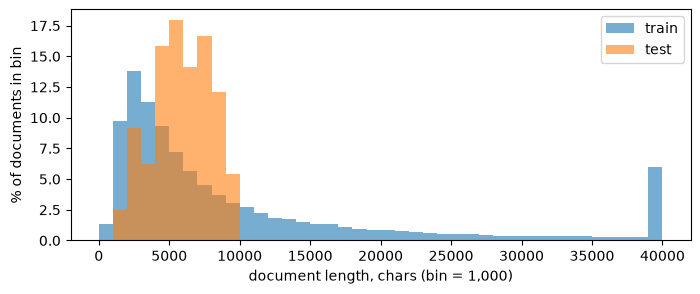

In [3]:
bins = np.arange(0, 41_000, 1_000)  # equal 1,000-char bins; train clipped at 40k (last bar = "≥40k")
fig, ax = plt.subplots(figsize=(8, 3))
for s, lab in [(train["len"].clip(upper=40_000), "train"), (test["len"], "test")]:
    ax.hist(s, bins=bins, weights=np.full(len(s), 100 / len(s)), alpha=.6, label=lab)
ax.set_xlabel("document length, chars (bin = 1,000)")
ax.set_ylabel("% of documents in bin")
ax.legend(); plt.show()

**Conclusion:** typical length is the same (~5.7k chars), but train has outliers up to 5.4M. We sample documents of 1–20k chars.

## 2. How much personal data of each type
- **train**: find placeholders (`ОСОБА_1`, …) in the text;
- **test**: use the `annotations`.

Columns:
- *mentions* — all occurrences;
- *unique entities* — distinct objects within a document (`ОСОБА_1` mentioned 4 times = 1);
- *docs with type* — how many documents contain the type at least once.

In [4]:
# train: all placeholders of each document -> list of (type, number) pairs
tr = train["text"].apply(lambda s: PH.findall(s))

# test: annotations (strip: one label has an extra space)
ann = pd.DataFrame([{**a, "id": r.id, "type": a["pseudonym"].strip().split("_")[0], "pseudonym": a["pseudonym"].strip()}
                    for r in test.itertuples() for a in r.annotations])
ann["len"] = ann["end"] - ann["start"]

counts = pd.DataFrame({
    "train: mentions": pd.Series([t for d in tr for t, _ in d]).value_counts(),
    "train: unique entities": pd.Series([t for d in tr for t, _ in set(d)]).value_counts(),
    "train: docs with type": pd.Series([t for d in tr for t in {t for t, _ in d}]).value_counts(),
    "test: mentions": ann["type"].value_counts(),
    "test: unique entities": ann.drop_duplicates(["id", "pseudonym"])["type"].value_counts(),
    "test: docs with type": ann.drop_duplicates(["id", "type"])["type"].value_counts(),
}).loc[TYPES]
counts

,train: mentions,train: unique entities,train: docs with type,test: mentions,test: unique entities,test: docs with type
ОСОБА,1079793,265502,36537,2837,862,236
АДРЕСА,105292,50086,21630,233,125,95
НОМЕР,214977,112387,16516,447,155,106
ІНФОРМАЦІЯ,163179,69348,20374,168,92,71


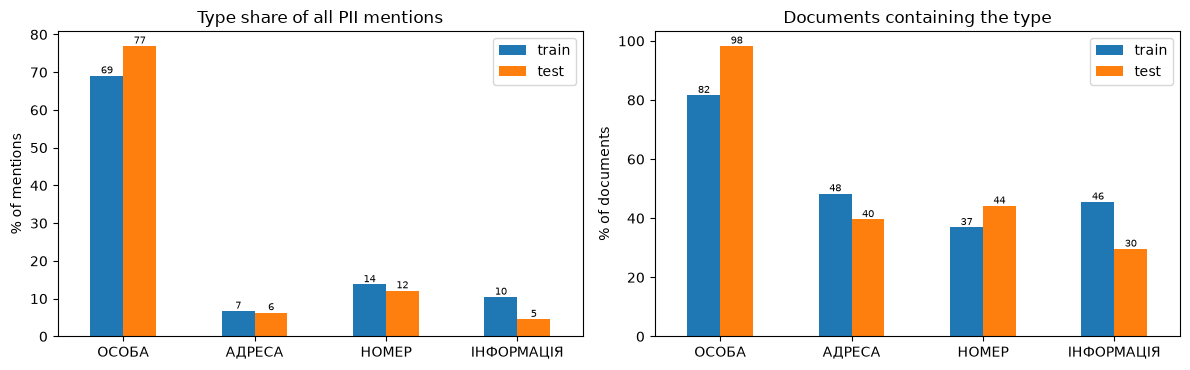

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
share = pd.DataFrame({"train": counts["train: mentions"] / counts["train: mentions"].sum() * 100,
                      "test": counts["test: mentions"] / counts["test: mentions"].sum() * 100})
share.plot.bar(ax=axes[0], rot=0); label_bars(axes[0])
axes[0].set_title("Type share of all PII mentions"); axes[0].set_ylabel("% of mentions")
docs = pd.DataFrame({"train": counts["train: docs with type"] / len(train) * 100,
                     "test": counts["test: docs with type"] / len(test) * 100})
docs.plot.bar(ax=axes[1], rot=0); label_bars(axes[1])
axes[1].set_title("Documents containing the type"); axes[1].set_ylabel("% of documents")
plt.tight_layout(); plt.show()

In [6]:
print("train: docs without placeholders:", (tr.str.len() == 0).sum(), f"({(tr.str.len() == 0).mean():.1%})")
print("test:  docs without annotations: ", (test["annotations"].str.len() == 0).sum())

train: docs without placeholders: 7308 (16.3%)
test:  docs without annotations:  0


**Conclusion:** `ОСОБА` is ~75% of all mentions; `ІНФОРМАЦІЯ` is the smallest type in test (168 mentions). Macro F1 weights all types equally, so rare types need more attention and data.

## 3. Personal data per document
For **each document** we compute two numbers:
- **PII mentions per doc** — occurrences of personal data of any type;
- **distinct persons per doc** — number of distinct `ОСОБА_N`.

The table is `describe()` over all documents. E.g. `50%` in "train: distinct persons" = the median train document has 2 persons.

In [7]:
test_persons = ann[ann.type == "ОСОБА"].groupby("id")["pseudonym"].nunique().reindex(test["id"], fill_value=0)
per_doc = pd.concat([
    pd.DataFrame({"train: PII mentions per doc": tr.str.len(),
                  "train: distinct persons per doc": tr.apply(lambda d: len({n for t, n in d if t == "ОСОБА"}))}).describe().T,
    pd.DataFrame({"test: PII mentions per doc": test["annotations"].str.len().values,
                  "test: distinct persons per doc": test_persons.values}).describe().T,
]).round(1)
per_doc

,count,mean,std,min,25%,50%,75%,max
train: PII mentions per doc,44758.0,34.9,198.0,0.0,4.0,11.0,25.0,16425.0
train: distinct persons per doc,44758.0,5.9,46.8,0.0,1.0,2.0,5.0,3923.0
test: PII mentions per doc,240.0,15.4,9.8,1.0,9.0,13.0,19.2,55.0
test: distinct persons per doc,240.0,3.6,2.9,0.0,1.0,3.0,5.0,18.0


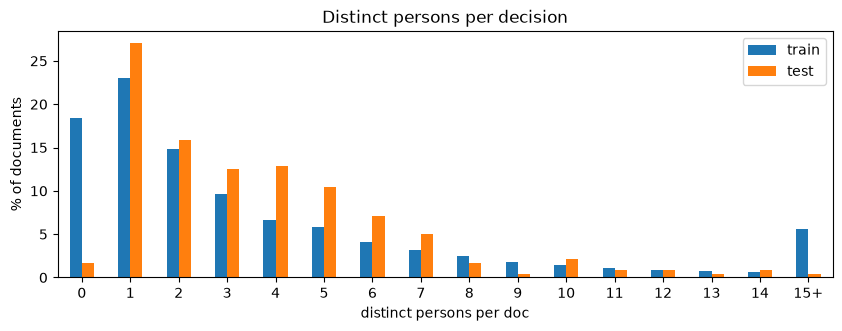

In [8]:
train_persons = tr.apply(lambda d: len({n for t, n in d if t == "ОСОБА"}))
dist = pd.DataFrame({"train": pct_dist(train_persons, 0, 15), "test": pct_dist(pd.Series(test_persons.values), 0, 15)})
ax = dist.plot.bar(figsize=(10, 3.2), rot=0)
ax.set_xlabel("distinct persons per doc"); ax.set_ylabel("% of documents"); ax.set_title("Distinct persons per decision")
plt.show()

**Conclusion:** a typical decision has 1–5 persons. 16% of train docs have no personal data, and some have thousands of persons, unlike test.

## 4. Mentions per entity in a document
For each entity (e.g. `ОСОБА_1` in doc X) we count its mentions. This matters for two metrics:
- **Deanonymization risk**: a person is exposed if **at least one** mention is missed. More mentions, easier to miss one.
- **Consistency**: all mentions must get the same code.

In [9]:
mpe_test = ann.groupby(["id", "pseudonym", "type"]).size().rename("mentions").reset_index()
mpe_train = pd.DataFrame([(t, c) for d in tr for (t, _), c in Counter(d).items()], columns=["type", "mentions"])
pd.concat({"train": mpe_train.groupby("type")["mentions"].describe().loc[TYPES],
           "test": mpe_test.groupby("type")["mentions"].describe().loc[TYPES]}).round(1)

count  mean   std  min  25%  50%  75%     max
      type                                                        
train ОСОБА       265502.0   4.1  15.7  1.0  1.0  2.0  3.0  2047.0
      АДРЕСА       50086.0   2.1   4.9  1.0  1.0  1.0  2.0   629.0
      НОМЕР       112387.0   1.9   5.2  1.0  1.0  1.0  2.0   968.0
      ІНФОРМАЦІЯ   69348.0   2.4   9.2  1.0  1.0  1.0  2.0   651.0
test  ОСОБА          862.0   3.3   3.0  1.0  1.0  2.0  4.0    25.0
      АДРЕСА         125.0   1.9   1.6  1.0  1.0  1.0  2.0     9.0
      НОМЕР          155.0   2.9   2.6  1.0  1.0  1.0  4.0    14.0
      ІНФОРМАЦІЯ      92.0   1.8   1.9  1.0  1.0  1.0  2.0    10.0

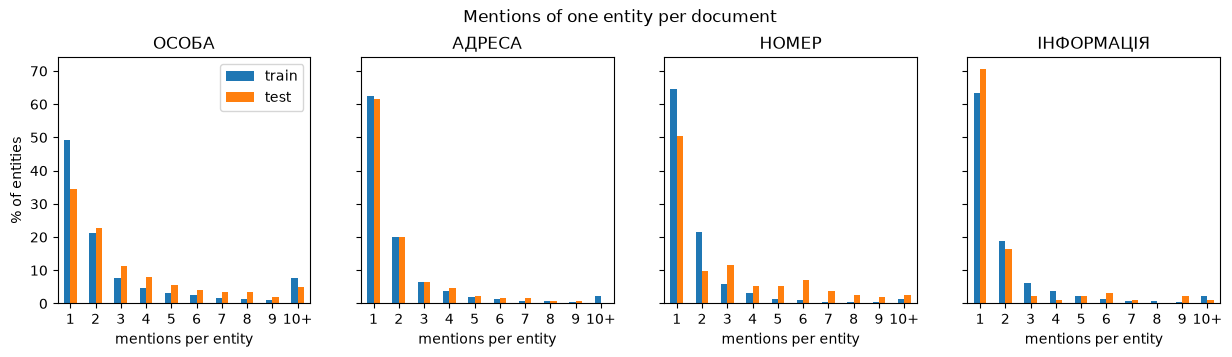

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, t in zip(axes, TYPES):
    pd.DataFrame({"train": pct_dist(mpe_train.loc[mpe_train.type == t, "mentions"], 1, 10),
                  "test": pct_dist(mpe_test.loc[mpe_test.type == t, "mentions"], 1, 10)}).plot.bar(ax=ax, rot=0, legend=(t == TYPES[0]))
    ax.set_title(t); ax.set_xlabel("mentions per entity")
axes[0].set_ylabel("% of entities")
plt.suptitle("Mentions of one entity per document", y=1.03); plt.show()

**Conclusion:** 50–65% of persons are mentioned more than once, some over 10 times. Addresses and dates are mostly mentioned once. Finding all repeat mentions of a person is a key pipeline step.

## 4b. Surface forms per person
Ukrainian is inflected, so one person is written differently: in different cases, in full or with initials. For each person in each test document we count distinct strings (`entity`).

Example: `Козоріз Андрій Ігорович` / `Козоріза Андрія Ігоровича` / `Козоріза А. І.` — 1 person, 3 forms.

**Test only**: train has no real names, only `ОСОБА_N`.

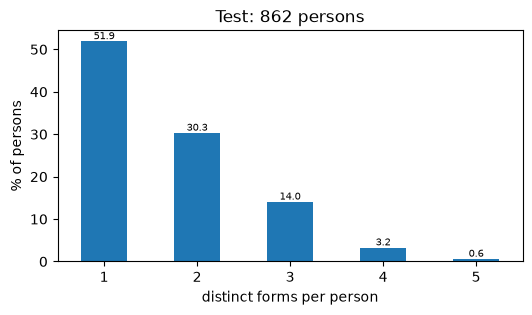

Persons with ≥3 forms:
  • Козоріз Андрій Ігорович  |  Козоріза Андрія Ігоровича  |  Козоріза А. І.
  • Кравець Олександр Володимирович  |  Кравця Олександра Володимировича  |  Кравцю Олександру Володимировичу
  • Кулика Романа Ігоровича  |  Кулику Роману Ігоровичу  |  Кулик Роман Ігорович
  • Потоцького Андрія Валерійовича  |  Потоцький Андрій Валерійович  |  Потоцькому Андрію Валерійовичу
  • Пинчук Богдан Сергійович  |  Пинчука Богдана Сергійовича  |  Пинчуку Богдану Сергійовичу


In [11]:
forms = ann[ann.type == "ОСОБА"].groupby(["id", "pseudonym"])["entity"].nunique()
v = forms.value_counts().sort_index()
ax = (v / v.sum() * 100).plot.bar(figsize=(6, 3), rot=0)
label_bars(ax, "%.1f")
ax.set_xlabel("distinct forms per person"); ax.set_ylabel("% of persons"); ax.set_title(f"Test: {v.sum()} persons")
plt.show()

print("Persons with ≥3 forms:")
for forms_list in ann[ann.type == "ОСОБА"].groupby(["id", "pseudonym"])["entity"].unique().loc[lambda s: s.str.len() >= 3].head(5):
    print("  •", "  |  ".join(forms_list))

**Conclusion:** ~48% of persons have 2–5 forms. The generator must inflect names and vary form; post-processing must merge forms into one person.

## 5. Entity length by type (test, chars) and examples
Useful for rules and for strict F1, where boundaries must match exactly.

In [12]:
ann.groupby("type")["len"].describe().loc[TYPES].round(1)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
ОСОБА,2837.0,24.7,5.5,5.0,23.0,26.0,28.0,39.0
АДРЕСА,233.0,56.8,17.5,14.0,45.0,56.0,70.0,96.0
НОМЕР,447.0,7.3,4.9,3.0,5.0,5.0,8.0,29.0
ІНФОРМАЦІЯ,168.0,33.4,27.3,9.0,10.0,24.0,49.0,96.0


In [13]:
for t in TYPES:
    print(t, "→", ann[ann.type == t]["entity"].drop_duplicates().sample(5, random_state=0).tolist())

ОСОБА → ['Онищенко Віталій Станіславович', 'Сметани Олексія Вікторовича', 'Савченко А.', 'Погребняк Віталій Андрійович', 'Кулику Роману Ігоровичу']
АДРЕСА → ['м. Київ, вулиця Саксаганського, будинок 51, квартира 36', '49000, Дніпро, проспект Гагаріна, 102', 'вул. Михайла Драй-Хмари, буд. 25, кв. 115, м. Київ, 03190', 'м. Бориспіль, вул. Київський Шлях, буд. 130, кв. 15', 'пров. Хлібний, 7']
НОМЕР → ['UA523206090000026005785235722', 'А4578', '543/2022/05', 'ВЧ23841', 'AB-8462-CH']
ІНФОРМАЦІЯ → ['2012-03-15', '2018-05-12', '1992-02-15', 'Військово-лікувальну комісію Центрального госпіталю Міністерства оборони України', '1988-03-27']


## 6. Train: names left in plain text
Registry rules do **not** depersonalize judges, lawyers, notaries, enforcement officers, public figures. In practice secretaries, prosecutors etc. also stay open. In train these names **appear as is, unmarked**, while in test all natural persons are labeled `ОСОБА`.

For each role, two document shares:
- **role word** — the doc contains «суддя», «секретар», … at all;
- **role + name** — the role word is followed (within 80 chars, same line) by a name `Surname I.P.` or `I.P. Surname`.

Rows **overlap**: a doc can have both judge and secretary, so the sum ≠ 100%. The rest are docs where the role is absent, has no name nearby (e.g. «судді Касаційного цивільного суду»), or the name is in another format (full). So this is a **lower bound**.

In [14]:
NAME = r"(?:[А-ЯІЇЄҐ][а-яіїєґ'’ʼ-]+\s+[А-ЯІЇЄҐ]\.\s?[А-ЯІЇЄҐ]\.|[А-ЯІЇЄҐ]\.\s?[А-ЯІЇЄҐ]\.\s?[А-ЯІЇЄҐ][а-яіїєґ'’ʼ-]+)"
ROLES = {"judge / presiding": r"[Сс]удд[яіею]|[Гг]оловуюч", "secretary": r"[Сс]екретар", "lawyer / defender": r"[Аа]двокат|[Зз]ахисник",
         "prosecutor": r"[Пп]рокурор", "notary": r"[Нн]отаріус", "enforcement officer": r"[Вв]иконав", "investigator": r"[Сс]лідч"}
role_hits = {r: train["text"].str.contains("(?:" + p + r")\w*[^\n]{0,80}?" + NAME) for r, p in ROLES.items()}
roles = pd.DataFrame({
    "% docs with role word": {r: train["text"].str.contains(p).mean() * 100 for r, p in ROLES.items()},
    "% docs: role + name": {r: h.mean() * 100 for r, h in role_hits.items()},
    "docs: role + name": {r: h.sum() for r, h in role_hits.items()},
}).round(1)
any_role = pd.concat(role_hits, axis=1).any(axis=1)
roles.loc["any role + name"] = [np.nan, any_role.mean() * 100, any_role.sum()]
roles

,% docs with role word,% docs: role + name,docs: role + name
judge / presiding,93.0,63.200000,28286
secretary,44.8,21.100000,9442
lawyer / defender,30.5,10.000000,4481
prosecutor,26.0,0.900000,420
notary,5.7,2.300000,1018
enforcement officer,22.4,1.300000,575
investigator,20.1,0.200000,72
any role + name,NaN,63.631083,28480


In [15]:
pat = re.compile("(?:" + ROLES["secretary"] + r")\w*[^\n]{0,80}?" + NAME)
print("Examples (secretary + name):")
for s in train["text"][role_hits["secretary"]].head(3):
    print("  •", re.sub(r"\s+", " ", pat.search(s).group(0)))

Examples (secretary + name):
  • секретарі Мех В.Ю.
  • секретаря |Лебідя В.Ю.
  • секретаря судового засідання Бугайової М.В.


**Conclusion:** an open judge name is in ~2/3 of docs, secretary in ~20%, lawyer in ~10%. The main task requires depersonalizing them ("all natural persons in the test set are depersonalized"); in test ~480 such mentions are labeled `ОСОБА`. So they must be labeled in training data too, or the model learns to skip them.

"Not subject to depersonalization" in the task applies only to the bonus task (finding leaks in the registry): there an open judge name is not a leak.

## 7. Sampling pool: train docs of 1–20k chars
Drop very long (up to 5.4M chars) and near-empty docs. The rest (the "pool") is used to generate training data.

In [16]:
pool = train[train["len"].between(1_000, 20_000)].copy()
pool_ph = pool["text"].apply(lambda s: PH.findall(s))
print(f"pool: {len(pool)} docs ({len(pool)/len(train):.0%} of train)")
pd.DataFrame({
    "docs with type": pd.Series([t for d in pool_ph for t in {t for t, _ in d}]).value_counts(),
    "mentions": pd.Series([t for d in pool_ph for t, _ in d]).value_counts(),
}).loc[TYPES].assign(**{"mentions per doc": lambda x: (x["mentions"] / x["docs with type"]).round(1)})

pool: 37577 docs (84% of train)


,docs with type,mentions,mentions per doc
ОСОБА,30914,429195,13.9
АДРЕСА,17261,48044,2.8
НОМЕР,12435,66729,5.4
ІНФОРМАЦІЯ,16573,67312,4.1


## 8. Subtypes of `ІНФОРМАЦІЯ` and `НОМЕР`
A placeholder does not say what it hides: a birth date or a military unit name. So we guess the subtype from the **left context** (~60 chars before it). Rules are tried in order; the first match wins. E.g.:
- `ОСОБА_1 , ІНФОРМАЦІЯ_1 , уродженця…` → birth date;
- `…який помер ІНФОРМАЦІЯ_3` → death date;
- `начальник ІНФОРМАЦІЯ_2` → institution or military unit name.

A **rough estimate**: the generator uses the same context rules.

In [17]:
SUB = {
 "ІНФОРМАЦІЯ": [
   ("death date",                 r"(помер\w*|смерт\w*)[^.]{0,40}$"),
   ("birth date",                 r"ОСОБА_\d+\s*,\s*$|народж|р\.\s?н\."),
   ("email / URL / nick",         r"e-?mail|пошт|http|www|сайт|нік|акаунт|телеграм|telegram|instagram|facebook|viber"),
   ("unit / institution name",    r"(начальник|командир|військов|частин|в/ч|ТЦК|центр|управлін|відділ|госпітал|КНП|ТОВ|комісі)\w*\W{0,4}$|[«\"]\s*$"),
 ],
 "НОМЕР": [
   ("tax ID (ІПН/РНОКПП)", r"ІПН|РНОКПП|ідентифікаційн|облікової картки"),
   ("passport",       r"паспорт"),
   ("phone",          r"тел\.|телефон|моб"),
   ("IBAN / account", r"IBAN|рахун"),
   ("license plate",  r"номерн\w* знак|д\.?н\.?з|реєстраційн\w* номер|автомобіл|транспортн"),
   ("military unit",  r"в/ч|військов\w* частин|ВЧ"),
   ("ID card / certificate", r"посвідчен|свідоцтв|сері"),
 ],
}
rows = []
for doc_id, text in zip(pool["id"], pool["text"]):
    for m in re.finditer(r"(ІНФОРМАЦІЯ|НОМЕР)_\d+", text):
        ctx = text[max(0, m.start() - 60):m.start()]
        sub = next((n for n, p in SUB[m.group(1)] if re.search(p, ctx, re.I)), "other / unclear")
        rows.append((doc_id, m.group(1), sub))
subs = pd.DataFrame(rows, columns=["id", "type", "subtype"])
tab = subs.groupby(["type", "subtype"]).agg(mentions=("id", "size"), docs=("id", "nunique"))
tab["% of type"] = (tab["mentions"] / tab.groupby(level=0)["mentions"].transform("sum") * 100).round(1)
tab = tab.sort_values(["type", "mentions"], ascending=[True, False])
tab

mentions   docs  % of type
type       subtype                                            
ІНФОРМАЦІЯ birth date                  33035  13474       49.1
           unit / institution name     16193   1657       24.1
           other / unclear             13362   4213       19.9
           death date                   3428   1158        5.1
           email / URL / nick           1294    582        1.9
НОМЕР      other / unclear             22249   3444       33.3
           phone                       12680   3280       19.0
           tax ID (ІПН/РНОКПП)         12195   5421       18.3
           license plate                6689   2173       10.0
           military unit                5477   1360        8.2
           ID card / certificate        3492   1437        5.2
           IBAN / account               2528    826        3.8
           passport                     1419    865        2.1

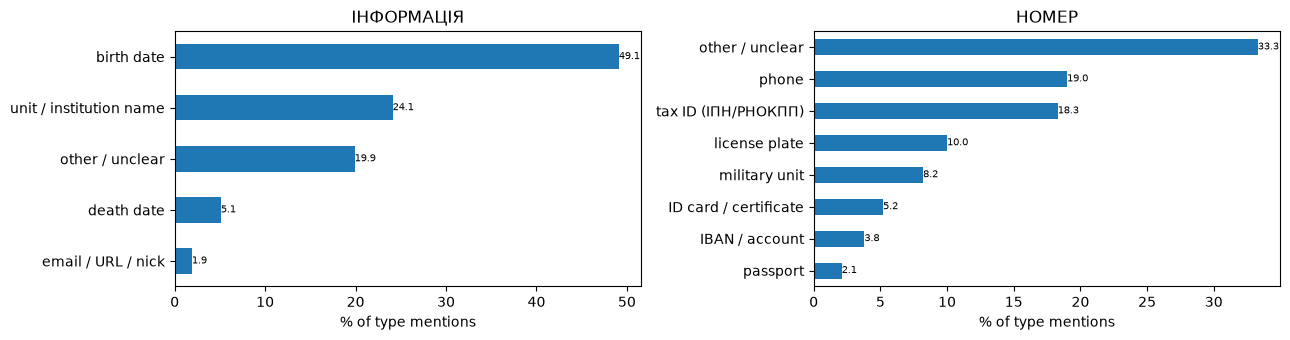

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, t in zip(axes, ["ІНФОРМАЦІЯ", "НОМЕР"]):
    s = tab.loc[t]["% of type"].sort_values()
    s.plot.barh(ax=ax); label_bars(ax, "%.1f")
    ax.set_title(t); ax.set_xlabel("% of type mentions"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Conclusion:** half of `ІНФОРМАЦІЯ` are birth dates, a quarter are unit and institution names. Email, URL and nicks are only ~2% (582 docs), so random sampling barely includes them. Hence we enrich the sample with rare subtypes.

## 9. Proceeding type and instance
Goal: split documents into groups (civil / criminal / …, first instance / appeal / cassation) so the training sample covers all of them.

**Proceeding number format:** `Провадження № 2-о/369/496/23`
- `2-о` — **category index** (gives type and instance);
- `369` — court code;
- `496` — sequence number;
- `23` — year.

The Supreme Court uses its own formats: `61-…ск23` (civil cassation), `51-…` (criminal), `К/9901/…` (administrative), `14-…цс20` (Grand Chamber).

**Rule check.** Do we read prefixes correctly? For each frequent prefix we check which procedural code its documents mention. Columns:
- *prefix* and *example number*;
- *meaning* — known index meaning, or "—" if inferred from data only;
- *our type* and *our instance* — what our rules assign;
- *% with our type's code* — share of docs mentioning the matching code. Closer to 100% = more reliable rule;
- then the share of docs mentioning each code (a doc can mention several).

In [19]:
PROV = re.compile(r"[Пп]ровадження\s*№\s*:?\s*([^\s,;|]+)")
KW = {"criminal": r"\bКПК\b|Кримінальн\w+ процесуальн", "admin offence": r"КУпАП|Кодекс\w* України про адміністративні правопорушення",
      "administrative": r"\bКАС\b|Кодекс\w* адміністративного судочинства", "civil": r"\bЦПК\b|Цивільн\w+ процесуальн",
      "commercial": r"\bГПК\b|Господарськ\w+ процесуальн"}
KW_NAME = {"criminal": "КПК", "admin offence": "КУпАП", "administrative": "КАС", "civil": "ЦПК", "commercial": "ГПК"}
UA = {"criminal": "criminal", "admin offence": "admin offence (КУпАП)", "administrative": "administrative (КАС)",
      "civil": "civil", "commercial": "commercial", "first": "first", "appeal": "appeal", "cassation": "cassation", "unknown": "?"}

# (type, instance) by number pattern; first matching rule wins
NUM_RULES = [
    (r"^61-\d+с[кцвз]|^1[1-4]-\d+цс",               ("civil", "cassation")),
    (r"^51-\d+",                                     ("criminal", "cassation")),
    (r"^К/\d+|^1[1-4]-\d+[аk]с|^11-\d+апп",         ("administrative", "cassation")),
    (r"^1[1-4]-\d+гс",                               ("commercial", "cassation")),
    (r"^11-?(кп|сс|п|в|кс)",                         ("criminal", "appeal")),
    (r"^22-?ц|^22-з",                                ("civil", "appeal")),
    (r"^22-?а",                                      ("administrative", "appeal")),
    (r"^33/|^23-з",                                  ("admin offence", "appeal")),
    (r"^1-?(кп|кс|в|во|кд|р|м|о|і|вп)\b|^1-?КП",     ("criminal", "first")),
    (r"^2-?а|^П/",                                   ("administrative", "first")),
    (r"^3/|^3-(в|зв)",                               ("admin offence", "first")),
    (r"^2/|^2-?[а-яіїє]+/|^4-с|^6/",                 ("civil", "first")),
]
def rule_for(number):
    return next((res for pat, res in NUM_RULES if re.search(pat, number)), None)

MEANING = {"3": "admin offence case", "2": "civil case (claim)",
           "1-кс": "motion to investigating judge", "1-кп": "criminal proceeding", "2-о": "special proceeding (facts etc.)",
           "22-ц": "civil appeal", "1-в": "sentence execution", "2-н": "writ proceeding", "11-кп": "criminal appeal",
           "2-а": "administrative case, local court", "33": "КУпАП appeal", "К": "administrative cassation (SC)",
           "2-з": "securing claim / evidence", "11-сс": "appeal of investigating judge rulings", "2-п": "review of default judgment"}

num = pool["text"].str.extract(PROV)[0]
pref = num.str.extract(r"^([^/]+)/")[0]
has_code = pd.DataFrame({k: pool["text"].str.contains(p) for k, p in KW.items()})
rows = []
for p_, n_docs in pref.value_counts().head(20).items():
    mask = (pref == p_).values
    example = num[mask].iloc[0]
    rule = rule_for(example)
    row = {"prefix": p_, "example number": example, "meaning": MEANING.get(p_, "—"), "docs": n_docs,
           "our type": UA[rule[0]] if rule else "unrecognized", "our instance": UA[rule[1]] if rule else "",
           "% with our type's code": round(has_code.loc[mask, rule[0]].mean() * 100) if rule else np.nan}
    row.update({f"% mention {KW_NAME[k]}": round(has_code.loc[mask, k].mean() * 100) for k in KW})
    rows.append(row)
pd.DataFrame(rows).set_index("prefix")

,example number,meaning,docs,our type,our instance,% with our type's code,% mention КПК,% mention КУпАП,% mention КАС,% mention ЦПК,% mention ГПК
prefix,,,,,,,,,,,
3,3/946/3143/23,admin offence case,3629,admin offence (КУпАП),first,98,5,98,1,1,0
2,2/127/4330/23,civil case (claim),3415,civil,first,94,1,1,0,94,1
1-кс,1-кс/505/2157/2023,motion to investigating judge,2714,criminal,first,96,96,1,0,0,0
1-кп,1-кп/753/119/23,criminal proceeding,1699,criminal,first,97,97,3,0,1,0
2-о,2-о/589/112/23,special proceeding (facts etc.),928,civil,first,95,1,1,1,95,0
22-ц,22-ц/817/1243/23,civil appeal,689,civil,appeal,92,0,0,1,92,1
1-в,1-в/368/13/24,sentence execution,449,criminal,first,87,87,14,0,1,0
6,6/369/496/23,—,410,civil,first,95,1,0,0,95,2
2-н,2-н/674/10/24,writ proceeding,321,civil,first,100,0,0,0,100,0


**Conclusion:** number rules are reliable: for most prefixes 87–100% of docs mention "their" code. Prefix `2-а` mentions both КАС and КУпАП: these are appeals of admin offence rulings in an administrative court.

**If there is no proceeding number** (~54% of pool, ~85% of test):
- **type** = most frequently mentioned code;
- **instance** = which complaint is decided: cassation + Supreme Court → cassation; appeal complaint → appeal; else the first court named in the first 1,500 chars.

The first court name alone is unreliable: test fragments start with case history («звернувся до районного суду…»).

In [20]:
COURT = [("cassation", r"Верховн\w+ Суд|Касаційн\w+ \w+ суд"), ("appeal", r"[Аа]пеляційн\w+ суд"),
         ("first", r"районн\w+ суд|міськрайонн\w+ суд|міськ\w+ суд|окружн\w+ \w*\s?суд|[Гг]осподарськ\w+ суд\w* (міста|\w+ області)")]

def type_by_keywords(text):
    c = {k: len(re.findall(p, text)) for k, p in KW.items()}
    return max(c, key=c.get) if max(c.values()) else "unknown"

def classify(text):
    m = PROV.search(text)
    if m and (rule := rule_for(m.group(1))):
        return (*rule, "number")
    if re.search(r"касаційн\w+ скарг", text) and re.search(r"Верховн\w+ Суд", text):
        inst = "cassation"
    elif re.search(r"(розглянув\w*|переглянув\w*)[^.]{0,150}апеляційн\w+ скарг"
                   r"|апеляційн\w+ скарг\w*[^.]{0,150}(задовольн|залиш\w+ без задоволення)", text):
        inst = "appeal"
    else:
        hits = [(mm.start(), lvl) for lvl, p in COURT if (mm := re.search(p, text[:1500]))]
        inst = min(hits)[1] if hits else "unknown"
    return type_by_keywords(text), inst, "keywords"

pool[["proceeding", "instance", "source"]] = pool["text"].apply(lambda t: pd.Series(classify(t)))
test[["proceeding", "instance", "source"]] = test["original"].apply(lambda t: pd.Series(classify(t)))
print("label source, pool:", pool["source"].value_counts(normalize=True).round(2).to_dict())
print("label source, test:", test["source"].value_counts(normalize=True).round(2).to_dict())

# agreement of fallback with number where both exist
by_num = pool[pool["source"] == "number"]
agree = (by_num["text"].apply(type_by_keywords) == by_num["proceeding"]).mean()
print(f"keyword type matches number type in {agree:.0%} of {len(by_num)} docs")

label source, pool: {'keywords': 0.54, 'number': 0.46}
label source, test: {'keywords': 0.85, 'number': 0.15}


keyword type matches number type in 95% of 17144 docs


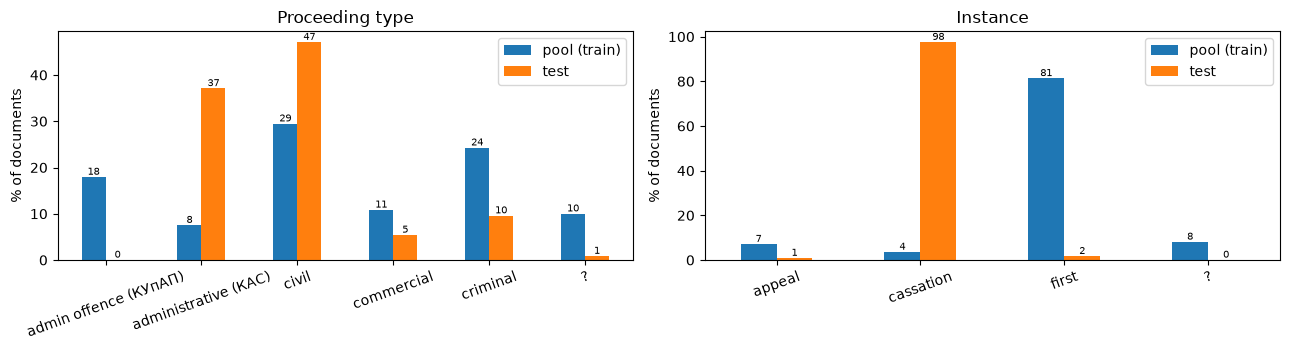

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, col, title in [(axes[0], "proceeding", "Proceeding type"), (axes[1], "instance", "Instance")]:
    d = pd.DataFrame({"pool (train)": pool[col].value_counts(normalize=True), "test": test[col].value_counts(normalize=True)}).mul(100).fillna(0)
    d.index = [UA.get(i, i) for i in d.index]
    d.plot.bar(ax=ax, rot=20); label_bars(ax)
    ax.set_title(title); ax.set_ylabel("% of documents")
plt.tight_layout(); plt.show()

**Sampling groups — type × instance.** Cell = number of pool docs. `All` = total.

In [22]:
pd.crosstab(pool["proceeding"].map(UA), pool["instance"].map(UA), margins=True)

instance,?,appeal,cassation,first,All
proceeding,,,,,
?,2410,35,36,1275,3756
admin offence (КУпАП),18,397,1,6322,6738
administrative (КАС),31,249,292,2254,2826
civil,56,1047,517,9450,11070
commercial,423,240,195,3212,4070
criminal,99,688,295,8035,9117
All,3037,2656,1336,30548,37577


Same for test: almost all cassation.

In [23]:
pd.crosstab(test["proceeding"].map(UA), test["instance"].map(UA), margins=True)

instance,appeal,cassation,first,All
proceeding,,,,
?,0,2,0,2
administrative (КАС),0,88,1,89
civil,2,110,1,113
commercial,0,13,0,13
criminal,0,21,2,23
All,2,234,4,240


## 9b. Document form: pool vs test
Share of docs with a given feature. Test is descriptive parts of Supreme Court cassation decisions **without a header**; train is full documents from various courts.

In [24]:
MARK = {"mentions «Верховний Суд»": r"Верховн\w* Суд", "mentions «касаційн…»": r"касаційн", "mentions «апеляційн…»": r"апеляційн",
        "starts with «Справа №» header": r"^\|?Справа", "has «ІМЕНЕМ УКРАЇНИ»": r"ІМЕНЕМ УКРАЇНИ|Іменем України"}
pd.DataFrame({k: {"pool, %": pool["text"].str.contains(p).mean(), "test, %": test["original"].str.contains(p).mean()}
              for k, p in MARK.items()}).T.mul(100).round(1)

,"pool, %","test, %"
mentions «Верховний Суд»,13.1,98.8
mentions «касаційн…»,6.8,95.4
mentions «апеляційн…»,53.3,95.4
starts with «Справа №» header,45.1,0.0
has «ІМЕНЕМ УКРАЇНИ»,34.7,2.1


## 10. Precision of per-type scores on the official test
If a model finds ~70% of a type, how precisely does the test measure it? Fewer examples, wider 95% CI. Formula: ±1.96·√(p(1−p)/n).

The intervals are underestimated: mentions in one document are not independent. Real ones are wider.

In [25]:
n = ann["type"].value_counts().loc[TYPES]
pd.DataFrame({"test mentions": n, "±95% CI, pp (recall≈0.7)": (1.96 * ((0.7 * 0.3) / n) ** 0.5 * 100).round(1)})

,test mentions,"±95% CI, pp (recall≈0.7)"
type,,
ОСОБА,2837,1.7
АДРЕСА,233,5.9
НОМЕР,447,4.2
ІНФОРМАЦІЯ,168,6.9


**Conclusion:** for `ІНФОРМАЦІЯ` the error is ±7 pp, so two systems 5 pp apart are indistinguishable. For subtypes (email, death date) the test gives no estimate. Hence we need our own larger, stratified test set.

---
# 11. Summary: how we build our data
The plan as written after this analysis; what changed during implementation is in `docs/DECISION_LOG.md`.

## Main idea
Train has no real names, only placeholders (`ОСОБА_1`, `АДРЕСА_1`, …). We **replace them with fake but realistic values** and record where they were inserted. This yields annotated docs in the test format (`original` + `annotations`), the same way the organizers built their test.

**Principle:** build data **for breadth, not for the official test**. The goal is detecting personal data in Ukrainian court texts in general; the official test is one narrow slice (SC cassation).

## Step 1. Document selection
| What | Why (section) |
|---|---|
| take docs of 1–20k chars → pool of 37,577 docs | train has outliers up to 5.4M chars (§1, §7) |
| stratify by **proceeding type × instance**: civil, criminal, КУпАП, administrative, commercial × first / appeal / cassation | train and test differ a lot: test is 98% cassation, train 4% (§9, §9b); each group has ≥195 docs |
| **enrich `ІНФОРМАЦІЯ`**: more *distinct* docs, rare subtypes first (death date, unit/institution names, email/URL/nick) | smallest type (168 test mentions), macro F1 weights types equally (§2); email/URL/nick in only 582 docs (§8) |
| **enrich rare `НОМЕР`**: IBAN, passport, license plates | 2–10% of the type each (§8) |
| add ~500 docs without personal data | the model must learn not to mask when there is nothing (§2: 16% of train) |

No **duplicate** docs: there are enough candidates for each type.

## Step 2. Value generation
| Type | How |
|---|---|
| `ОСОБА` | one fake person per `ОСОБА_N` in a doc (Ukrainian name dictionary). **rules + `pymorphy3`** pick the case (an LLM was tested and lost, see `DECISION_LOG.md`); form varies per mention: full name, `Surname I. P.`, `I.P. Surname` (§4b: 48% of persons have 2–5 forms) |
| `АДРЕСА` | fake addresses in various formats (`вул.`/`вулиця`, with or without postcode) |
| `НОМЕР` | context rules pick the subtype (tax ID, phone, IBAN, plate, unit…); code generates a well-formed value, with checksum where needed |
| `ІНФОРМАЦІЯ` | context rules pick the subtype (birth / death date, unit name, email…); code generates the value; dates in various formats: `15.02.1992`, `1992-02-15`, `15 лютого 1992 року` |

**The text is never rewritten**: code only inserts values, so the rest of the text is unchanged and entity offsets are exact.

## Step 3. Open names in train
Names of judges, secretaries, lawyers, notaries and enforcement officers in train are **not depersonalized** (~64% of docs, §6), but the main task requires it. We find them with rules and **label them `ОСОБА`**, otherwise the model learns to skip them.

## Step 4. Splits
Split **by document `id`** so no doc is in both training and evaluation.

| Set | Size | Purpose |
|---|---|---|
| **Train** | ~6,000 docs | model training |
| **Dev** | ~300 docs, same stratification | model selection, thresholds |
| **Our test A** | ~500 docs, ≥50 per "type × instance" group | overall quality, metrics **per group** |
| **Our test B** | ≥100 mentions per `ІНФОРМАЦІЯ` / `НОМЕР` subtype | reliable rare-subtype estimates (§10: official test too small) |
| **Official test** | 240 docs | transfer check on SC cassation decisions; **never used for tuning** |

## Step 5. Quality control
1. Manually review ~30 generated docs: cases, gender, naturalness.
2. For our tests use **a different name list and formats** than for train, so the model does not "recognize" the generator.
3. Report results **on both tests** (ours and official) with CIs. Ours is more optimistic (same generator), so the official one is less biased.